### **RANDOM FOREST FUNGSI MANUAL**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# NODE
# ============================================================
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf_node(self):
        return self.value is not None

# ============================================================
# DECISION TREE
# ============================================================
class DecisionTree:
    def __init__(self, min_samples_split=2, max_depth=100, n_features=None,
                 max_thresholds=None):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.n_features = n_features
        # max_thresholds: opsional, None = cek semua nilai unik
        self.max_thresholds = max_thresholds
        self.root = None

    def fit(self, X, y):
        self.n_features = X.shape[1] if not self.n_features else min(X.shape[1], self.n_features)
        self.root = self._grow_tree(X, y)

    def _grow_tree(self, X, y, depth=0):
        n_samples, n_feats = X.shape
        n_labels = len(np.unique(y))

        if (depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split):
            leaf_value = self._most_common_label(y)
            return Node(value=leaf_value)

        feat_idxs = np.random.choice(n_feats, self.n_features, replace=False)
        best_feature, best_thresh = self._best_split(X, y, feat_idxs)

        if best_feature is None:
            leaf_value = self._most_common_label(y)
            return Node(value=leaf_value)

        left_idxs, right_idxs = self._split(X[:, best_feature], best_thresh)
        left = self._grow_tree(X[left_idxs, :], y[left_idxs], depth + 1)
        right = self._grow_tree(X[right_idxs, :], y[right_idxs], depth + 1)

        return Node(best_feature, best_thresh, left, right)

    def _best_split(self, X, y, feat_idxs):
        best_gain = -1
        split_idx, split_threshold = None, None

        for feat_idx in feat_idxs:
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)

            if self.max_thresholds is not None and len(thresholds) > self.max_thresholds:
                percentiles = np.linspace(0, 100, self.max_thresholds)
                thresholds = np.unique(np.percentile(X_column, percentiles))

            for thr in thresholds:
                gain = self._gini_gain(y, X_column, thr)

                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_threshold = thr

        return split_idx, split_threshold

    # ========================================================
    # GINI GAIN
    # ========================================================
    def _gini_gain(self, y, X_column, threshold):
        parent_gini = self._gini(y)
        left_idxs, right_idxs = self._split(X_column, threshold)

        if len(left_idxs) == 0 or len(right_idxs) == 0:
            return -1  # split tidak valid (salah satu sisi kosong) -> -1 supaya tidak pernah terpilih sebagai split terbaik

        n = len(y)
        n_l, n_r = len(left_idxs), len(right_idxs)

        gini_left = self._gini(y[left_idxs])
        gini_right = self._gini(y[right_idxs])

        child_gini = (n_l / n) * gini_left + (n_r / n) * gini_right
        return parent_gini - child_gini

    def _split(self, X_column, split_thresh):
        left_idxs = np.argwhere(X_column <= split_thresh).flatten()
        right_idxs = np.argwhere(X_column > split_thresh).flatten()
        return left_idxs, right_idxs

    # ========================================================
    # Gini IMPURITY
    # ========================================================
    def _gini(self, y):
        hist = np.bincount(y)
        ps = hist / len(y)
        return 1 - np.sum(ps ** 2)

    def _most_common_label(self, y):
        counter = Counter(y)
        return counter.most_common(1)[0][0]

    def predict(self, X):
        return np.array([self._traverse_tree(x, self.root) for x in X])

    def _traverse_tree(self, x, node):
        if node.is_leaf_node():
            return node.value

        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)

        return self._traverse_tree(x, node.right)


In [ ]:
# ============================================================
# RANDOM FOREST
# ============================================================

class RandomForest:
    def __init__(self, n_trees=10, max_depth=10, min_samples_split=2,
                 n_features=None, max_thresholds=None, bootstrap=True, verbose=True):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.n_features = n_features
        self.max_thresholds = max_thresholds
        self.bootstrap = bootstrap
        self.verbose = verbose
        self.trees = []

    def fit(self, X, y):
        self.trees = []

        for i in range(self.n_trees):
            t0 = time.time()

            tree = DecisionTree(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                n_features=self.n_features,
                max_thresholds=self.max_thresholds,
            )

            # ========================================================
            # Bootstrasp sampling:
            # ========================================================
            if self.bootstrap:
                X_sample, y_sample = self._bootstrap_samples(X, y)
            else:
                X_sample, y_sample = X, y

            tree.fit(X_sample, y_sample)
            self.trees.append(tree)

            if self.verbose:
                print(f"    [pohon {i+1}/{self.n_trees}] selesai ({time.time()-t0:.1f} detik)")

    def _bootstrap_samples(self, X, y):
        n_samples = X.shape[0]
        idxs = np.random.choice(n_samples, n_samples, replace=True)
        return X[idxs], y[idxs]

    def _most_common_label(self, y):
        counter = Counter(y)
        return counter.most_common(1)[0][0]

    def predict(self, X):
        predictions = np.array([tree.predict(X) for tree in self.trees])
        tree_preds = np.swapaxes(predictions, 0, 1)
        predictions = np.array([self._most_common_label(pred) for pred in tree_preds])

        return predictions

In [ ]:
import os
import glob
import time
import numpy as np
import pandas as pd
import rasterio
from collections import Counter
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, cohen_kappa_score, classification_report
)

# Path files
SKRIPSI_DIR = "/content/drive/MyDrive/Colab Notebooks/skripsi"
FEATURES_ROOT = os.path.join(SKRIPSI_DIR, "kecamatan_masked_pchip")
LABELS_ROOT = os.path.join(SKRIPSI_DIR, "kecamatan_masked_ndbi")

# Kota/kabupaten
SELECTED_KOTA = [
    "kota_tangerang",
    "kota_tangerang_selatan",
    "kabupaten_tangerang",
]

# Fitur input klasifikasi
BANDS_FEATURES = ["B02", "B03", "B04", "B05", "B06", "B07", "B12"]
LABEL_NODATA = 255

# Jumlah sampel yang diambi per kombinasi (kecamatan, tanggal) untuk efisiensi waktu komputasi
N_SAMPLES_PER_DATE = 150

# Berapa persen kecamatan yang disisihkan total sebagai data uji (spatial split)
TEST_KECAMATAN_FRACTION = 0.2

RANDOM_STATE = 42

In [ ]:
# ============================================================
# CEK LOKASI BAND DAN KECAMATAN
# ============================================================

def find_band(date_dir, band):
    files = glob.glob(os.path.join(date_dir, f"*_{band}_10m.tif"))
    if len(files) == 0:
        raise FileNotFoundError(f"{band} tidak ditemukan: {date_dir}")
    return files[0]


def discover_kecamatan(kota_dir):
    return sorted([
        d for d in os.listdir(kota_dir) if os.path.isdir(os.path.join(kota_dir, d))
    ])


In [ ]:
def load_sample_for_date(kota, kecamatan, date_name, rng):
    """
    Baca 9 band (fitur) dari kecamatan_masked_pchip dan label dari
    kecamatan_masked_ndbi, untuk 1 kecamatan + 1 tanggal.
    Ambil sampel acak N_SAMPLES_PER_DATE piksel yang valid (bukan nodata).
    """
    feat_dir = os.path.join(FEATURES_ROOT, kota, kecamatan, date_name)
    label_dir = os.path.join(LABELS_ROOT, kota, kecamatan, date_name)

    label_files = glob.glob(os.path.join(label_dir, "NDBI_LABEL_*.tif"))
    if not label_files:
        return None, None

    with rasterio.open(label_files[0]) as src:
        label = src.read(1)

    valid_mask = label != LABEL_NODATA
    if valid_mask.sum() == 0:
        return None, None

    bands_data = []
    for band in BANDS_FEATURES:
        try:
            band_path = find_band(feat_dir, band)
        except FileNotFoundError:
            return None, None
        with rasterio.open(band_path) as src:
            bands_data.append(src.read(1).astype(np.float32))

    stack = np.stack(bands_data, axis=-1)  # (H, W, 9)

    valid_idx = np.argwhere(valid_mask)
    n_sample = min(N_SAMPLES_PER_DATE, len(valid_idx))
    chosen = rng.choice(len(valid_idx), size=n_sample, replace=False)
    rows, cols = valid_idx[chosen, 0], valid_idx[chosen, 1]

    X = stack[rows, cols, :]
    y = label[rows, cols].astype(np.int64)  # int64 supaya aman dipakai np.bincount di RF manual
    return X, y


def build_pooled_dataset(kota_list, rng):
    X_all, y_all = [], []
    kecamatan_all = []   # dipakai nanti untuk spatial split

    for kota in kota_list:
        kota_dir = os.path.join(FEATURES_ROOT, kota)
        if not os.path.isdir(kota_dir):
            print(f"[skip] folder tidak ditemukan: {kota_dir}")
            continue

        kecamatan_list = discover_kecamatan(kota_dir)
        print(f"\n{'='*60}")
        print(f"KOTA: {kota} -- {len(kecamatan_list)} kecamatan ditemukan")
        print(f"{'='*60}")

        for kecamatan in kecamatan_list:
            kec_dir = os.path.join(kota_dir, kecamatan)
            date_folders = sorted([
                d for d in os.listdir(kec_dir) if os.path.isdir(os.path.join(kec_dir, d))
            ])

            n_collected = 0
            for date_name in date_folders:
                X, y = load_sample_for_date(kota, kecamatan, date_name, rng)
                if X is None:
                    continue
                X_all.append(X)
                y_all.append(y)
                kecamatan_all.extend([f"{kota}__{kecamatan}"] * len(y))
                n_collected += len(y)

            print(f"  {kecamatan:25s} : {n_collected:6,} piksel dari {len(date_folders)} tanggal")

    X = np.concatenate(X_all, axis=0)
    y = np.concatenate(y_all, axis=0)
    kecamatan_arr = np.array(kecamatan_all)

    print(f"\n{'-'*60}")
    print(f"TOTAL dataset gabungan : {len(y):,} piksel")
    print(f"  Terbangun (1)        : {(y==1).sum():,}")
    print(f"  Non-terbangun (0)    : {(y==0).sum():,}")
    print(f"  Total kecamatan unik : {len(np.unique(kecamatan_arr))}")

    return X, y, kecamatan_arr

# ============================================================
# CACHING DATASET (untuk simpan ke drive kalau nanti proses ke-stop)
# ============================================================
CACHE_FILE = os.path.join(SKRIPSI_DIR, "pooled_dataset_cache.npz")

if os.path.exists(CACHE_FILE):
    print(f"Membaca dataset dari cache: {CACHE_FILE}")
    print("Mohon tunggu sebentar...")

    # Load data dari file .npz
    data_cache = np.load(CACHE_FILE)
    X = data_cache['X']
    y = data_cache['y']
    kecamatan_arr = data_cache['kecamatan_arr']

    print(f"Berhasil dimuat!")
    print(f"TOTAL dataset gabungan : {len(y):,} piksel")
    print(f"  Terbangun (1)        : {(y==1).sum():,}")
    print(f"  Non-terbangun (0)    : {(y==0).sum():,}")
else:
    print("Cache tidak ditemukan. Memulai proses ekstraksi dari awal...")
    print("Proses ini akan memakan waktu lama, mohon ditunggu.")

    rng = np.random.default_rng(RANDOM_STATE)
    X, y, kecamatan_arr = build_pooled_dataset(SELECTED_KOTA, rng)

    print("\nMenyimpan dataset ke dalam cache agar eksekusi selanjutnya cepat...")
    # Simpan array ke dalam satu file .npz terkompresi
    np.savez_compressed(CACHE_FILE, X=X, y=y, kecamatan_arr=kecamatan_arr)
    print(f"Dataset berhasil disimpan di: {CACHE_FILE}")

# rng = np.random.default_rng(RANDOM_STATE)
# X, y, kecamatan_arr = build_pooled_dataset(SELECTED_KOTA, rng)

Membaca dataset dari cache: /content/drive/MyDrive/Colab Notebooks/skripsi/pooled_dataset_cache.npz
Mohon tunggu sebentar...
Berhasil dimuat!
TOTAL dataset gabungan : 470,400 piksel
  Terbangun (1)        : 231,303
  Non-terbangun (0)    : 239,097


In [ ]:
# ============================================================
# TRAIN-TEST SPLIT
# ============================================================
def spatial_train_test_split(X, y, kecamatan_arr, test_fraction, random_state):
    """
    Split BUKAN acak per piksel -- tapi acak per KECAMATAN (spatial split),
    supaya kecamatan uji benar-benar tidak pernah dilihat model saat training.
    Ini menghindari overestimasi akurasi akibat autokorelasi spasial
    (piksel bertetangga sangat mirip -- lihat Dejoux dkk.).

    Selain X dan y, fungsi ini juga mengembalikan kecamatan milik setiap baris
    (kec_train, kec_test) -- dipakai sebagai groups pada Grid Search.
    """
    unique_kec = np.unique(kecamatan_arr)
    rng_local = np.random.default_rng(random_state)
    rng_local.shuffle(unique_kec)

    n_test = max(1, int(len(unique_kec) * test_fraction))
    test_kec = set(unique_kec[:n_test])
    train_kec = set(unique_kec[n_test:])

    train_mask = np.array([k in train_kec for k in kecamatan_arr])
    test_mask = ~train_mask

    print(f"Kecamatan TRAIN ({len(train_kec)}): {sorted(train_kec)}")
    print(f"Kecamatan TEST  ({len(test_kec)}): {sorted(test_kec)}")

    return (X[train_mask], X[test_mask], y[train_mask], y[test_mask],
            kecamatan_arr[train_mask], kecamatan_arr[test_mask])


X_train, X_test, y_train, y_test, kec_train, kec_test = spatial_train_test_split(
    X, y, kecamatan_arr, TEST_KECAMATAN_FRACTION, RANDOM_STATE
)

print(f"\nData latih : {len(y_train):,} piksel")
print(f"Data uji   : {len(y_test):,} piksel")

Kecamatan TRAIN (40): [np.str_('kabupaten_tangerang__balaraja'), np.str_('kabupaten_tangerang__cikupa'), np.str_('kabupaten_tangerang__cisauk'), np.str_('kabupaten_tangerang__cisoka'), np.str_('kabupaten_tangerang__curug'), np.str_('kabupaten_tangerang__jambe'), np.str_('kabupaten_tangerang__jayanti'), np.str_('kabupaten_tangerang__kelapa_dua'), np.str_('kabupaten_tangerang__kemiri'), np.str_('kabupaten_tangerang__kosambi'), np.str_('kabupaten_tangerang__kresek'), np.str_('kabupaten_tangerang__kronjo'), np.str_('kabupaten_tangerang__legok'), np.str_('kabupaten_tangerang__mauk'), np.str_('kabupaten_tangerang__mekar_baru'), np.str_('kabupaten_tangerang__pagedangan'), np.str_('kabupaten_tangerang__pakuhaji'), np.str_('kabupaten_tangerang__panongan'), np.str_('kabupaten_tangerang__pasar_kemis'), np.str_('kabupaten_tangerang__sepatan'), np.str_('kabupaten_tangerang__sepatan_timur'), np.str_('kabupaten_tangerang__solear'), np.str_('kabupaten_tangerang__sukamulya'), np.str_('kabupaten_tangera

In [ ]:
import json
import pandas as pd
from joblib import Parallel, delayed
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ============================================================
# GRID SEARCH HYPERPARAMETER RANDOM FOREST (BISA DILANJUTKAN)
# ============================================================
# - Setiap hasil (1 kombinasi x 1 lipatan) langsung ditambahkan ke CSV di Drive.
#   Kalau sesi terputus / sel dihentikan, jalankan sel ini lagi: bagian yang sudah
#   selesai dilewati otomatis.
# - Pencarian HANYA memakai data latih (X_train). Data uji (X_test) tidak disentuh.
# - Validasi silang PER KECAMATAN (GroupKFold), konsisten dengan spatial split di atas.

# 1. Tentukan nilai parameter mtry (n_features)
# mtry = sqrt(jumlah fitur) -- rujukan Šćepanović dkk. (2021), MDPI Remote Sensing
n_features_mtry = int(np.sqrt(X_train.shape[1]))

# 2. Definisikan kombinasi yang ingin diuji (Dictionary)
param_grid = {
    'n_trees': [10, 30],
    'max_depth': [8, 12, 16],
    'min_samples_split': [2, 5, 10],
    'n_features': [n_features_mtry, n_features_mtry + 1],
    'max_thresholds': [20],
    'bootstrap': [True],
    'verbose': [False]
}

# 3. Subsampel data latih khusus untuk tuning (waktu training ~ linear terhadap jumlah baris)
# 0.25 = pakai 25% baris X_train (acak, semua kecamatan tetap terwakili). Isi 1.0 untuk data latih penuh.
# Model akhir (sel training di bawah) TETAP dilatih pada seluruh X_train.
FRAKSI_TUNING = 1;
if FRAKSI_TUNING < 1.0:
    rng_tuning = np.random.default_rng(RANDOM_STATE)
    idx_tuning = np.sort(rng_tuning.choice(len(y_train), int(len(y_train) * FRAKSI_TUNING), replace=False))
else:
    idx_tuning = np.arange(len(y_train))
X_tune, y_tune, kec_tune = X_train[idx_tuning], y_train[idx_tuning], kec_train[idx_tuning]
print(f"Data tuning : {len(y_tune):,} piksel dari {len(np.unique(kec_tune))} kecamatan")

# 4. Lipatan validasi silang: tiap kecamatan hanya muncul di satu lipatan
N_LIPATAN = 3
cv_splits = list(GroupKFold(n_splits=N_LIPATAN).split(X_tune, y_tune, groups=kec_tune))

# 5. Satu tugas = satu kombinasi hyperparameter x satu lipatan
def jalankan_satu_fit(params, fold, X, y, idx_tr, idx_va):
    t0 = time.time()
    model = RandomForest(**params)
    model.fit(X[idx_tr], y[idx_tr])
    waktu_latih = time.time() - t0

    t0 = time.time()
    y_pred = model.predict(X[idx_va])
    waktu_prediksi = time.time() - t0

    y_va = y[idx_va]
    baris = {k: v for k, v in params.items() if k != 'verbose'}
    baris.update({
        'fold': fold,
        'akurasi': accuracy_score(y_va, y_pred),
        'precision': precision_score(y_va, y_pred),
        'recall': recall_score(y_va, y_pred),
        'f1': f1_score(y_va, y_pred),
        'waktu_latih_dtk': waktu_latih,
        'waktu_prediksi_dtk': waktu_prediksi,
    })
    return baris

def kunci_tugas(params, fold):
    p = {k: v for k, v in params.items() if k != 'verbose'}
    return json.dumps(p, sort_keys=True) + f"|{fold}"

# 6. Baca progres yang sudah tersimpan (kalau ada)
PROGRESS_PATH = os.path.join(SKRIPSI_DIR, f"grid_search_progress_tuning{FRAKSI_TUNING}.csv")
nama_param = [k for k in param_grid if k != 'verbose']
kombinasi = list(ParameterGrid(param_grid))

selesai = set()
if os.path.exists(PROGRESS_PATH):
    df_lama = pd.read_csv(PROGRESS_PATH)
    for _, r in df_lama.iterrows():
        p = {k: r[k].item() if hasattr(r[k], 'item') else r[k] for k in nama_param}
        selesai.add(kunci_tugas(p, int(r['fold'])))

tugas = [(p, f) for p in kombinasi for f in range(N_LIPATAN) if kunci_tugas(p, f) not in selesai]
total_semua = len(kombinasi) * N_LIPATAN
print(f"Total tugas : {total_semua} | sudah selesai : {len(selesai)} | sisa : {len(tugas)}")

# Urutan diacak (seed tetap) supaya perkiraan sisa waktu tidak bias oleh kombinasi yang mahal/murah
np.random.default_rng(RANDOM_STATE).shuffle(tugas)

# 7. Jalankan paralel; tiap hasil langsung ditambahkan ke CSV begitu selesai
print("Memulai Grid Search...")
t_mulai = time.time()
hasil_stream = Parallel(n_jobs=-1, return_as='generator_unordered')(
    delayed(jalankan_satu_fit)(p, f, X_tune, y_tune, cv_splits[f][0], cv_splits[f][1])
    for p, f in tugas
)

for n, baris in enumerate(hasil_stream, 1):
    pd.DataFrame([baris]).to_csv(PROGRESS_PATH, mode='a', header=not os.path.exists(PROGRESS_PATH), index=False)
    elapsed = time.time() - t_mulai
    sisa_menit = elapsed / n * (len(tugas) - n) / 60
    print(f"[{len(selesai) + n}/{total_semua}] "
          f"trees={baris['n_trees']} depth={baris['max_depth']} mss={baris['min_samples_split']} "
          f"mtry={baris['n_features']} fold={baris['fold']} | akurasi={baris['akurasi']:.4f} "
          f"| latih {baris['waktu_latih_dtk']:.0f}s | sisa +/- {sisa_menit:.0f} menit")

print(f"\nSelesai. Total waktu sesi ini: {(time.time() - t_mulai) / 60:.1f} menit")
print(f"Progres tersimpan di: {PROGRESS_PATH}")

Data tuning : 384,000 piksel dari 40 kecamatan
Total tugas : 108 | sudah selesai : 0 | sisa : 108
Memulai Grid Search...
[1/108] trees=10 depth=8 mss=5 mtry=3 fold=0 | akurasi=0.9029 | latih 74s | sisa +/- 165 menit
[2/108] trees=30 depth=8 mss=10 mtry=3 fold=0 | akurasi=0.9037 | latih 213s | sisa +/- 227 menit
[3/108] trees=30 depth=8 mss=10 mtry=2 fold=1 | akurasi=0.9004 | latih 144s | sisa +/- 256 menit
[4/108] trees=10 depth=12 mss=5 mtry=3 fold=2 | akurasi=0.9153 | latih 264s | sisa +/- 313 menit
[5/108] trees=10 depth=8 mss=2 mtry=2 fold=0 | akurasi=0.9005 | latih 47s | sisa +/- 269 menit
[6/108] trees=10 depth=8 mss=10 mtry=2 fold=0 | akurasi=0.8973 | latih 47s | sisa +/- 239 menit
[7/108] trees=30 depth=16 mss=2 mtry=2 fold=0 | akurasi=0.9120 | latih 1216s | sisa +/- 332 menit
[8/108] trees=30 depth=12 mss=10 mtry=3 fold=2 | akurasi=0.9173 | latih 767s | sisa +/- 347 menit
[9/108] trees=30 depth=12 mss=5 mtry=2 fold=1 | akurasi=0.9079 | latih 526s | sisa +/- 360 menit
[10/108] 

In [ ]:
# ============================================================
# REKAP GRID SEARCH: 10 MODEL TERBAIK
# ============================================================
# Sel ini bisa dijalankan kapan saja setelah sel di atas dihentikan/selesai.
# Hanya kombinasi dengan semua lipatan lengkap yang diperingkat.
from IPython.display import display

df_progress = pd.read_csv(PROGRESS_PATH)

df_agg = df_progress.groupby(nama_param).agg(
    akurasi=('akurasi', 'mean'),
    std_akurasi=('akurasi', lambda s: np.std(s)),
    precision=('precision', 'mean'),
    recall=('recall', 'mean'),
    f1=('f1', 'mean'),
    waktu_latih_dtk=('waktu_latih_dtk', 'mean'),
    waktu_prediksi_dtk=('waktu_prediksi_dtk', 'mean'),
    n_lipatan=('fold', 'count'),
).reset_index()

n_belum_lengkap = (df_agg['n_lipatan'] < N_LIPATAN).sum()
print(f"Kombinasi lengkap : {(df_agg['n_lipatan'] == N_LIPATAN).sum()} dari {len(kombinasi)}")
if n_belum_lengkap > 0 or len(df_agg) < len(kombinasi):
    print("PERINGATAN: Grid Search belum selesai seluruhnya, peringkat di bawah BELUM final.")

df_agg = df_agg[df_agg['n_lipatan'] == N_LIPATAN].drop(columns=['n_lipatan'])
df_agg = df_agg.sort_values(by=['akurasi', 'waktu_latih_dtk'], ascending=[False, True]).reset_index(drop=True)
df_agg.index = df_agg.index + 1  # peringkat mulai dari 1
df_agg.index.name = 'peringkat'

# Hyperparameter terbaik (diubah ke tipe Python biasa supaya aman disimpan ke JSON)
best_params = {k: (v.item() if hasattr(v, 'item') else v) for k, v in df_agg.iloc[0][nama_param].items()}
best_params['verbose'] = False

print("\n" + "="*50)
print(f"Parameter Terbaik : {best_params}")
print(f"Akurasi Terbaik   : {df_agg.iloc[0]['akurasi']:.4f}")
print("="*50)

# Cek apakah nilai terbaik berada di tepi grid (kalau ya, grid sebaiknya diperluas)
for nama, nilai in param_grid.items():
    if len(nilai) > 1 and best_params[nama] in (min(nilai), max(nilai)):
        print(f"Catatan: {nama} terbaik = {best_params[nama]} berada di tepi grid {nilai}")

# akurasi/precision/recall/f1 = rata-rata antar-lipatan, std_akurasi = simpangan baku antar-lipatan
print("\n10 MODEL TERBAIK (urut berdasarkan akurasi rata-rata validasi silang per kecamatan)")
display(df_agg.head(10).round(4))

# Simpan rekap ke Drive
GRID_RESULTS_PATH = os.path.join(SKRIPSI_DIR, "grid_search_results.csv")
BEST_PARAMS_PATH = os.path.join(SKRIPSI_DIR, "rf_best_params.json")

df_agg.to_csv(GRID_RESULTS_PATH)
with open(BEST_PARAMS_PATH, "w") as f:
    json.dump(best_params, f, indent=4)

print(f"\nRekap {len(df_agg)} kombinasi tersimpan ke : {GRID_RESULTS_PATH}")
print(f"Hyperparameter terbaik tersimpan ke : {BEST_PARAMS_PATH}")
# Kalau sesi terputus, muat ulang hyperparameter terbaik dengan:
# best_params = json.load(open(BEST_PARAMS_PATH))

Kombinasi lengkap : 36 dari 36

Parameter Terbaik : {'n_trees': 30, 'max_depth': 16, 'min_samples_split': 10, 'n_features': 3, 'max_thresholds': 20, 'bootstrap': True, 'verbose': False}
Akurasi Terbaik   : 0.9138
Catatan: n_trees terbaik = 30 berada di tepi grid [10, 30]
Catatan: max_depth terbaik = 16 berada di tepi grid [8, 12, 16]
Catatan: min_samples_split terbaik = 10 berada di tepi grid [2, 5, 10]
Catatan: n_features terbaik = 3 berada di tepi grid [2, 3]

10 MODEL TERBAIK (urut berdasarkan akurasi rata-rata validasi silang per kecamatan)


,n_trees,max_depth,min_samples_split,n_features,max_thresholds,bootstrap,akurasi,std_akurasi,precision,recall,f1,waktu_latih_dtk,waktu_prediksi_dtk
peringkat,,,,,,,,,,,,,
1,30,16,10,3,20,True,0.9138,0.0034,0.9114,0.9135,0.9124,1722.3060,66.1933
2,30,16,2,3,20,True,0.9134,0.0031,0.9110,0.9131,0.9120,1806.0595,66.6363
3,30,16,5,3,20,True,0.9133,0.0031,0.9103,0.9137,0.9119,1773.3720,67.5871
4,30,16,2,2,20,True,0.9133,0.0032,0.9113,0.9124,0.9118,1107.4245,58.1406
5,30,16,5,2,20,True,0.9132,0.0033,0.9109,0.9128,0.9118,1263.2906,67.9671
6,30,16,10,2,20,True,0.9132,0.0037,0.9114,0.9121,0.9117,1204.9890,67.5797
7,30,12,5,3,20,True,0.9129,0.0032,0.9099,0.9132,0.9115,762.8139,55.8751
8,30,12,10,3,20,True,0.9127,0.0035,0.9104,0.9122,0.9113,752.7089,55.9789
9,30,12,2,3,20,True,0.9127,0.0035,0.9106,0.9119,0.9112,776.7568,55.7265



Rekap 36 kombinasi tersimpan ke : /content/drive/MyDrive/Colab Notebooks/skripsi/grid_search_results.csv
Hyperparameter terbaik tersimpan ke : /content/drive/MyDrive/Colab Notebooks/skripsi/rf_best_params.json


In [ ]:
import os
import time
import pickle
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)
# Hyperparameter sama persis dengan model utama (hasil Grid Search), hanya bootstrap yang dimatikan
print(f"Hyperparameter hasil Grid Search : {best_params}")
# ============================================================
# 1. Training Model TANPA Bootstrap
# ============================================================
print("=== Training Random Forest (TANPA Bootstrap) ===")
rf_manual = RandomForest(
    n_trees=best_params['n_trees'],
    max_depth=best_params['max_depth'],
    min_samples_split=best_params['min_samples_split'],
    n_features=best_params['n_features'],
    max_thresholds=best_params['max_thresholds'],
    bootstrap=True,
    verbose=True
)

t0 = time.time()
rf_manual.fit(X_train, y_train)
print(f"\nTotal waktu training: {time.time() - t0:.1f} detik")

# ============================================================
# 2. Evaluasi Model pada Data Uji (Spatial Test)
# ============================================================
y_pred_no_boot = rf_manual.predict(X_test)

cm = confusion_matrix(y_test, y_pred_no_boot)
oa = accuracy_score(y_test, y_pred_no_boot)
precision = precision_score(y_test, y_pred_no_boot)
recall = recall_score(y_test, y_pred_no_boot)
f1 = f1_score(y_test, y_pred_no_boot)

print("\n" + "="*60)
print("=== HASIL EVALUASI MODEL (TANPA BOOTSTRAP) ===")
print("="*60)
print("=== Confusion Matrix ===")
print(f"                       Prediksi Non-Terbangun   Prediksi Terbangun")
print(f"Aktual Non-Terbangun        {cm[0,0]:>10,}              {cm[0,1]:>10,}")
print(f"Aktual Terbangun            {cm[1,0]:>10,}              {cm[1,1]:>10,}")

print(f"\n=== Metrik Evaluasi (dievaluasi di kecamatan yang TIDAK pernah dilihat model) ===")
print(f"Overall Accuracy : {oa:.4f}")
print(f"Precision        : {precision:.4f}")
print(f"Recall           : {recall:.4f}")
print(f"F1-Score         : {f1:.4f}")

print(f"\n=== Classification Report ===")
print(classification_report(y_test, y_pred_no_boot, target_names=["Non-Terbangun", "Terbangun"]))

# ============================================================
# 3. Simpan Model Tanpa Bootstrap ke Drive
# ============================================================
MODEL_PATH_NO_BOOT = os.path.join(SKRIPSI_DIR, "rf_manual_model_1.pkl")

with open(MODEL_PATH_NO_BOOT, "wb") as f:
    pickle.dump(rf_no_bootstrap, f)

print("="*60)
print(f"Model berhasil tersimpan ke: {MODEL_PATH_NO_BOOT}")
print(f"Ukuran file: {os.path.getsize(MODEL_PATH_NO_BOOT) / 1024:.1f} KB")
print("="*60)

Hyperparameter hasil Grid Search : {'n_trees': 30, 'max_depth': 16, 'min_samples_split': 10, 'n_features': 3, 'max_thresholds': 20, 'bootstrap': True, 'verbose': False}
=== Training Random Forest (TANPA Bootstrap) ===
    [pohon 1/30] selesai (48.4 detik)
    [pohon 2/30] selesai (52.4 detik)
    [pohon 3/30] selesai (48.3 detik)
    [pohon 4/30] selesai (49.5 detik)
    [pohon 5/30] selesai (51.6 detik)
    [pohon 6/30] selesai (50.0 detik)
    [pohon 7/30] selesai (52.0 detik)
    [pohon 8/30] selesai (52.2 detik)
    [pohon 9/30] selesai (54.1 detik)
    [pohon 10/30] selesai (52.0 detik)
    [pohon 11/30] selesai (51.6 detik)
    [pohon 12/30] selesai (53.3 detik)
    [pohon 13/30] selesai (49.1 detik)
    [pohon 14/30] selesai (52.3 detik)
    [pohon 15/30] selesai (54.1 detik)
    [pohon 16/30] selesai (49.2 detik)
    [pohon 17/30] selesai (47.9 detik)
    [pohon 18/30] selesai (54.4 detik)
    [pohon 19/30] selesai (52.2 detik)
    [pohon 20/30] selesai (53.7 detik)
    [pohon 

Hyperparameter hasil Grid Search : {'n_trees': 30, 'max_depth': 16, 'min_samples_split': 10, 'n_features': 3, 'max_thresholds': 20, 'bootstrap': True, 'verbose': False}
=== Training Random Forest (DENGAN Bootstrap) ===
    [pohon 1/30] selesai (43.1 detik)
    [pohon 2/30] selesai (43.0 detik)
    [pohon 3/30] selesai (40.4 detik)
    [pohon 4/30] selesai (41.8 detik)
    [pohon 5/30] selesai (41.7 detik)
    [pohon 6/30] selesai (43.1 detik)
    [pohon 7/30] selesai (39.7 detik)
    [pohon 8/30] selesai (42.8 detik)
    [pohon 9/30] selesai (44.0 detik)
    [pohon 10/30] selesai (44.3 detik)
    [pohon 11/30] selesai (41.5 detik)
    [pohon 12/30] selesai (40.5 detik)
    [pohon 13/30] selesai (44.6 detik)
    [pohon 14/30] selesai (44.5 detik)
    [pohon 15/30] selesai (40.0 detik)
    [pohon 16/30] selesai (41.3 detik)
    [pohon 17/30] selesai (41.9 detik)
    [pohon 18/30] selesai (43.2 detik)
    [pohon 19/30] selesai (42.9 detik)
    [pohon 20/30] selesai (43.2 detik)
    [pohon

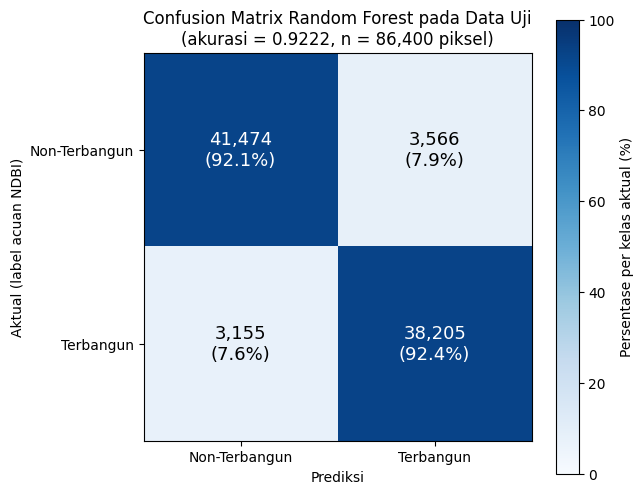

Plot confusion matrix tersimpan ke: /content/drive/MyDrive/Colab Notebooks/skripsi/confusion_matrix_rf_test.png
Model berhasil tersimpan ke: /content/drive/MyDrive/Colab Notebooks/skripsi/rf_manual_model_1.pkl
Ukuran file: 28094.7 KB


In [ ]:
import os
import time
import pickle
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)
# Hyperparameter model utama diambil dari hasil Grid Search
print(f"Hyperparameter hasil Grid Search : {best_params}")
# ============================================================
# 1. Training Model DENGAN Bootstrap
# ============================================================
print("=== Training Random Forest (DENGAN Bootstrap) ===")
rf_manual = RandomForest(
    n_trees=best_params['n_trees'],
    max_depth=best_params['max_depth'],
    min_samples_split=best_params['min_samples_split'],
    n_features=best_params['n_features'],
    max_thresholds=best_params['max_thresholds'],
    bootstrap=True,
    verbose=True
)

t0 = time.time()
rf_manual.fit(X_train, y_train)
print(f"\nTotal waktu training: {time.time() - t0:.1f} detik")

# ============================================================
# 2. Evaluasi Model pada Data Uji (Spatial Test)
# ============================================================
y_pred_no_boot = rf_manual.predict(X_test)

cm = confusion_matrix(y_test, y_pred_no_boot)
oa = accuracy_score(y_test, y_pred_no_boot)
precision = precision_score(y_test, y_pred_no_boot)
recall = recall_score(y_test, y_pred_no_boot)
f1 = f1_score(y_test, y_pred_no_boot)

print("\n" + "="*60)
print("=== HASIL EVALUASI MODEL (DENGAN BOOTSTRAP) ===")
print("="*60)
print("=== Confusion Matrix ===")
print(f"                       Prediksi Non-Terbangun   Prediksi Terbangun")
print(f"Aktual Non-Terbangun        {cm[0,0]:>10,}              {cm[0,1]:>10,}")
print(f"Aktual Terbangun            {cm[1,0]:>10,}              {cm[1,1]:>10,}")

print(f"\n=== Metrik Evaluasi (dievaluasi di kecamatan yang TIDAK pernah dilihat model) ===")
print(f"Overall Accuracy : {oa:.4f}")
print(f"Precision        : {precision:.4f}")
print(f"Recall           : {recall:.4f}")
print(f"F1-Score         : {f1:.4f}")

print(f"\n=== Classification Report ===")
print(classification_report(y_test, y_pred_no_boot, target_names=["Non-Terbangun", "Terbangun"]))

# ============================================================
# 2b. Plot Confusion Matrix
# ============================================================
nama_kelas = ["Non-Terbangun", "Terbangun"]
cm_persen = cm / cm.sum(axis=1, keepdims=True) * 100  # persentase per baris (kelas aktual) = recall tiap kelas

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm_persen, cmap="Blues", vmin=0, vmax=100)

for i in range(2):
    for j in range(2):
        warna = "white" if cm_persen[i, j] > 50 else "black"
        ax.text(j, i, f"{cm[i, j]:,}\n({cm_persen[i, j]:.1f}%)",
                ha="center", va="center", color=warna, fontsize=13)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(nama_kelas)
ax.set_yticklabels(nama_kelas)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual (label acuan NDBI)")
ax.set_title(f"Confusion Matrix Random Forest pada Data Uji\n(akurasi = {oa:.4f}, n = {cm.sum():,} piksel)")
fig.colorbar(im, ax=ax, label="Persentase per kelas aktual (%)")
plt.tight_layout()

PLOT_CM_PATH = os.path.join(SKRIPSI_DIR, "confusion_matrix_rf_test.png")
plt.savefig(PLOT_CM_PATH, dpi=300, bbox_inches="tight")  # simpan dulu sebelum show()
plt.show()
print(f"Plot confusion matrix tersimpan ke: {PLOT_CM_PATH}")

# ============================================================
# 3. Simpan Model ke Drive
# ============================================================
MODEL_PATH_NO_BOOT = os.path.join(SKRIPSI_DIR, "rf_manual_model_1.pkl")

with open(MODEL_PATH_NO_BOOT, "wb") as f:
    pickle.dump(rf_manual, f)

print("="*60)
print(f"Model berhasil tersimpan ke: {MODEL_PATH_NO_BOOT}")
print(f"Ukuran file: {os.path.getsize(MODEL_PATH_NO_BOOT) / 1024:.1f} KB")
print("="*60)

In [ ]:
from IPython.display import display

# ============================================================
# Akurasi per Kecamatan Uji (seberapa stabil hasil antar kecamatan?)
# ============================================================
# Unit data uji sebenarnya adalah KECAMATAN (9 kecamatan), bukan piksel.
# Tabel ini menunjukkan seberapa besar hasil berubah dari satu kecamatan ke kecamatan lain.
hasil_kec = []
for kec in np.unique(kec_test):
    m = kec_test == kec
    hasil_kec.append({
        'kecamatan': kec,
        'n_piksel': int(m.sum()),
        'akurasi': accuracy_score(y_test[m], y_pred_no_boot[m]),
        'recall_terbangun': recall_score(y_test[m], y_pred_no_boot[m], zero_division=0),
        'persen_terbangun_acuan': y_test[m].mean() * 100,
    })
df_kec_uji = pd.DataFrame(hasil_kec).sort_values('akurasi').reset_index(drop=True)
display(df_kec_uji.round(4))

print(f"Akurasi rata-rata antar kecamatan : {df_kec_uji['akurasi'].mean():.4f}")
print(f"Simpangan baku antar kecamatan    : {df_kec_uji['akurasi'].std(ddof=0):.4f}")
print(f"Akurasi terendah - tertinggi      : {df_kec_uji['akurasi'].min():.4f} - {df_kec_uji['akurasi'].max():.4f}")

,kecamatan,n_piksel,akurasi,recall_terbangun,persen_terbangun_acuan
0,kota_tangerang_selatan__serpong,9600,0.8840,0.9136,48.4896
1,kota_tangerang_selatan__setu,9600,0.9060,0.9131,43.7500
2,kabupaten_tangerang__sindang_jaya,9600,0.9121,0.8289,35.0625
3,kota_tangerang__neglasari,9600,0.9133,0.9223,52.5625
4,kabupaten_tangerang__rajeg,9600,0.9216,0.8795,37.9479
5,kota_tangerang__jatiuwung,9600,0.9332,0.9665,77.3438
6,kota_tangerang__ciledug,9600,0.9395,0.9839,80.1354
7,kabupaten_tangerang__gunung_kaler,9600,0.9418,0.8830,33.3958
8,kabupaten_tangerang__sukadiri,9600,0.9484,0.8904,22.1458


Akurasi rata-rata antar kecamatan : 0.9222
Simpangan baku antar kecamatan    : 0.0194
Akurasi terendah - tertinggi      : 0.8840 - 0.9484


In [ ]:
import pickle

# Simpan model
MODEL_PATH = os.path.join(SKRIPSI_DIR, "rf_manual_model_1.pkl")

# Run setelah setelah rf_manual.fit() selesai
with open(MODEL_PATH, "wb") as f:
    pickle.dump(rf_manual, f)

print(f"Model tersimpan ke: {MODEL_PATH}")
print(f"Ukuran file: {os.path.getsize(MODEL_PATH) / 1024:.1f} KB")

Model tersimpan ke: /content/drive/MyDrive/Colab Notebooks/skripsi/rf_manual_model_1.pkl
Ukuran file: 28094.7 KB


In [ ]:
# Import model
MODEL_PATH = os.path.join(SKRIPSI_DIR, "rf_manual_model_1.pkl")

with open(MODEL_PATH, "rb") as f:
    rf_manual = pickle.load(f)

print("Model berhasil dimuat dari Drive, tidak perlu training ulang.")
print(f"Jumlah pohon: {len(rf_manual.trees)}")

In [ ]:
import os
import glob
import time
import numpy as np
import rasterio

RF_OUTPUT_ROOT = os.path.join(SKRIPSI_DIR, "kecamatan_masked_rf_classified")

# True  = klasifikasi ULANG semua raster. WAJIB setelah model berubah (mis. hyperparameter baru hasil Grid Search),
#         kalau tidak, raster lama dari model sebelumnya akan dilewati dan bercampur dengan raster baru.
# False = lewati raster yang sudah ada. Hanya pakai untuk MELANJUTKAN proses yang terputus dengan model yang sama.
OVERWRITE = True
print(f"OVERWRITE = {OVERWRITE}")


def classify_full_raster(kota, kecamatan, date_name, model):
    feat_dir = os.path.join(FEATURES_ROOT, kota, kecamatan, date_name)
    out_dir = os.path.join(RF_OUTPUT_ROOT, kota, kecamatan, date_name)

    out_path = os.path.join(out_dir, f"RF_LABEL_{date_name}.tif")
    if os.path.exists(out_path) and not OVERWRITE:
        return "skip"

    bands_data = []
    profile_ref = None
    for band in BANDS_FEATURES:
        try:
            band_path = find_band(feat_dir, band)
        except FileNotFoundError:
            return "band_missing"
        with rasterio.open(band_path) as src:
            bands_data.append(src.read(1).astype(np.float32))
            if profile_ref is None:
                profile_ref = src.profile.copy()

    stack = np.stack(bands_data, axis=-1)  # (H, W, 7)
    h, w, _ = stack.shape

    valid_mask = stack[:, :, 0] != 0  # piksel di luar kecamatan = 0 di semua band

    flat = stack.reshape(-1, len(BANDS_FEATURES))
    pred_flat = model.predict(flat)  # RF manual kamu
    pred_map = pred_flat.reshape(h, w).astype(np.uint8)

    pred_map[~valid_mask] = LABEL_NODATA  # tandai luar wilayah, konsisten dgn NDBI_LABEL

    os.makedirs(out_dir, exist_ok=True)
    out_profile = profile_ref.copy()
    out_profile.update(count=1, dtype="uint8", nodata=LABEL_NODATA, compress="lzw")
    with rasterio.open(out_path, "w", **out_profile) as dst:
        dst.write(pred_map, 1)

    return "ok"


# ============================================================
# Loop semua kota -> kecamatan -> tanggal
# ============================================================
log_rows = []
for kota in SELECTED_KOTA:
    kota_dir = os.path.join(FEATURES_ROOT, kota)
    for kecamatan in discover_kecamatan(kota_dir):
        kec_dir = os.path.join(kota_dir, kecamatan)
        date_folders = sorted([d for d in os.listdir(kec_dir) if os.path.isdir(os.path.join(kec_dir, d))])

        print(f"\n{kota}/{kecamatan} -- {len(date_folders)} tanggal")
        for date_name in date_folders:
            t0 = time.time()
            status = classify_full_raster(kota, kecamatan, date_name, rf_manual)
            print(f"  [{status}] {date_name} ({time.time()-t0:.1f}s)")
            log_rows.append({"kota": kota, "kecamatan": kecamatan, "tanggal": date_name, "status": status})

pd.DataFrame(log_rows).to_csv(os.path.join(SKRIPSI_DIR, "rf_classification_log.csv"), index=False)
print("\nSelesai klasifikasi penuh.")